# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [1]:
!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [2]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [2]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


Matplotlib is building the font cache; this may take a moment.


## Test NIM availability

In [3]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

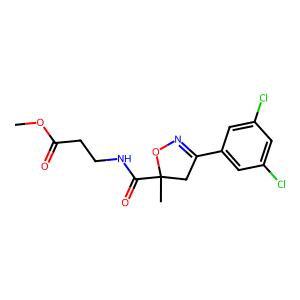

In [4]:
#Seed 1
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [8]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [9]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1
SAFE:   C16(C)CC(c2cc(Cl)cc(Cl)c2)=NO1.C3(=O)CC5.C46=O.CO3.N45
 represented using 5 fragments


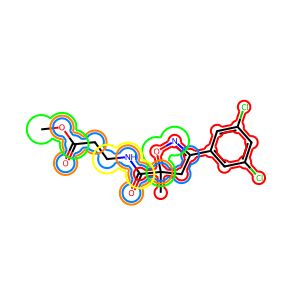

In [10]:
sf.to_image(safe_str)

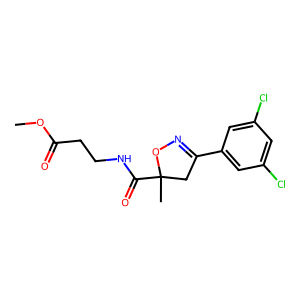

In [11]:
testreconstructed = dm.to_mol(safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [31]:
result = gm.produce([m_seq], 10)

In [32]:
print(result[0])
print(m_seq)

Cc1cccc(NCCc2cccc(C(=O)[O-])c2)c1
COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1


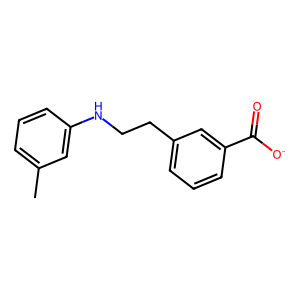

In [33]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

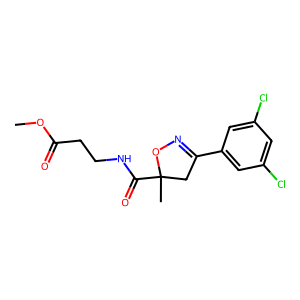

In [74]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

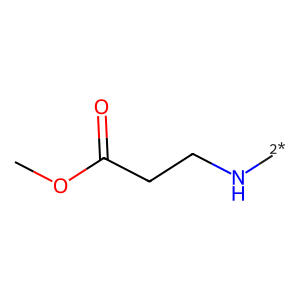

In [113]:
# add wildcard to a fragment
smiles_masked_1 = 'COC(=O)CCN[2*]' #'COC(=O)CCNC(C[2*])=O'  #'[2*](c2cc(Cl)cc(Cl)c2)' // '[2*]NC(=O)C1(C)CC([3*])=NO1' // 'COC(=O)CCN[2*]' // COC(=O)CCNC(C[2*])=O
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [114]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules = gm.inference(smiles = safe_to_gen + '.[*{8-20}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules)

40

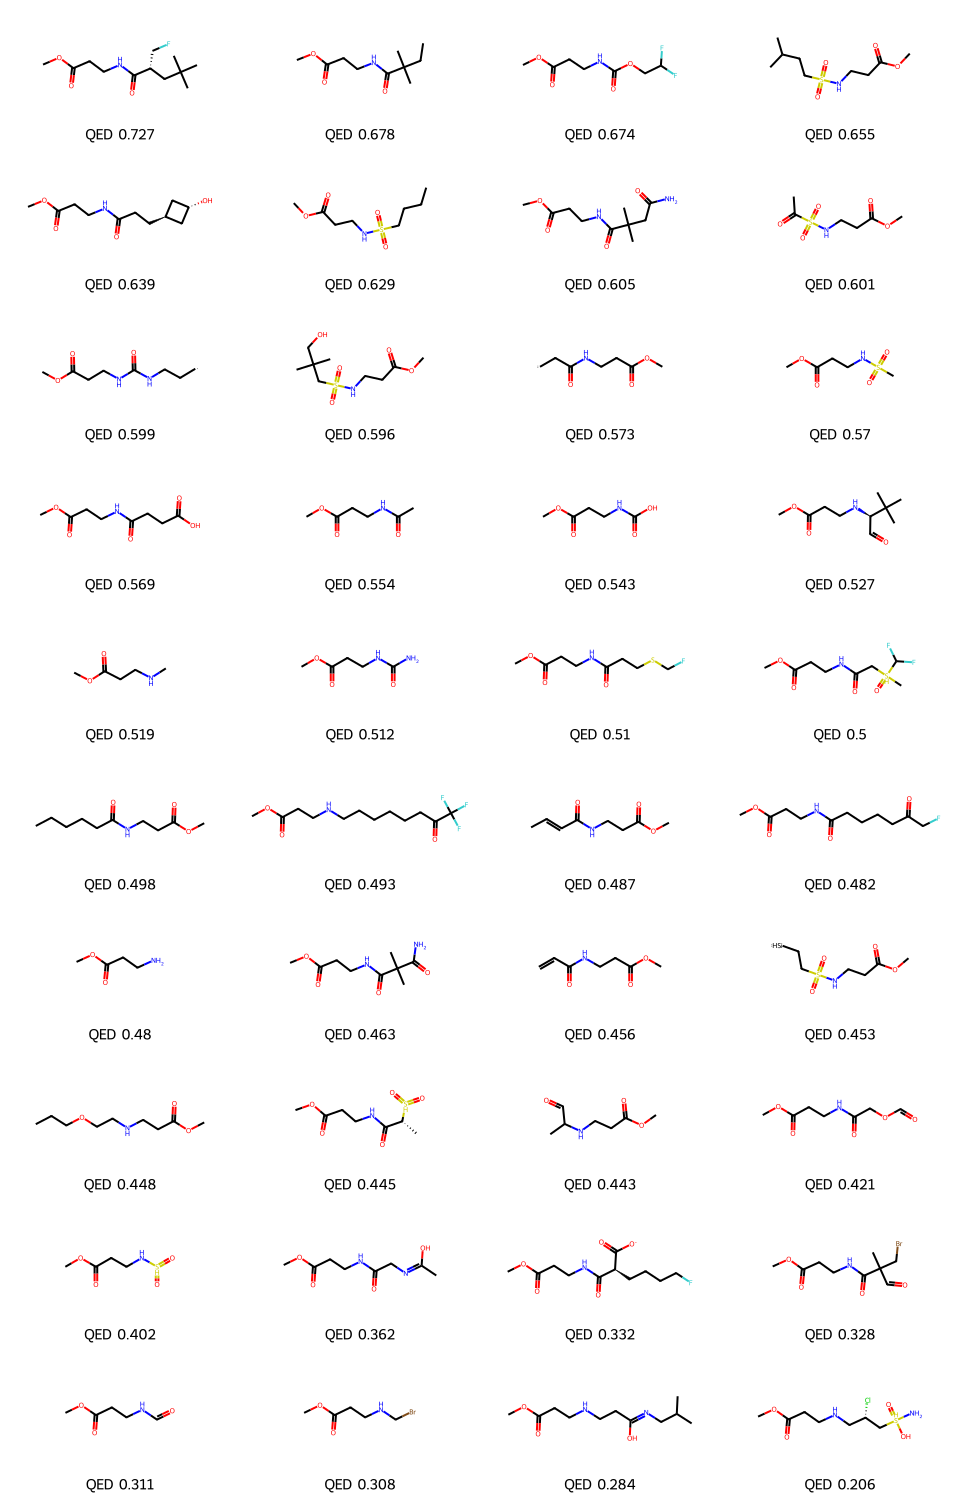

In [115]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules])

In [67]:
# Create a DataFrame
df_results = pd.DataFrame(molecules)


## Example 2: second fragment

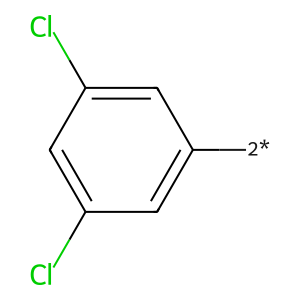

In [116]:
# add wildcard to a fragment
smiles_masked_1 = '[2*](c2cc(Cl)cc(Cl)c2)'  #'[2*](c2cc(Cl)cc(Cl)c2)' // '[2*]NC(=O)C1(C)CC([3*])=NO1' // 'COC(=O)CCN[2*]' // COC(=O)CCNC(C[2*])=O
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [78]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules = gm.inference(smiles = safe_to_gen + '.[*{10-20}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules)

57

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


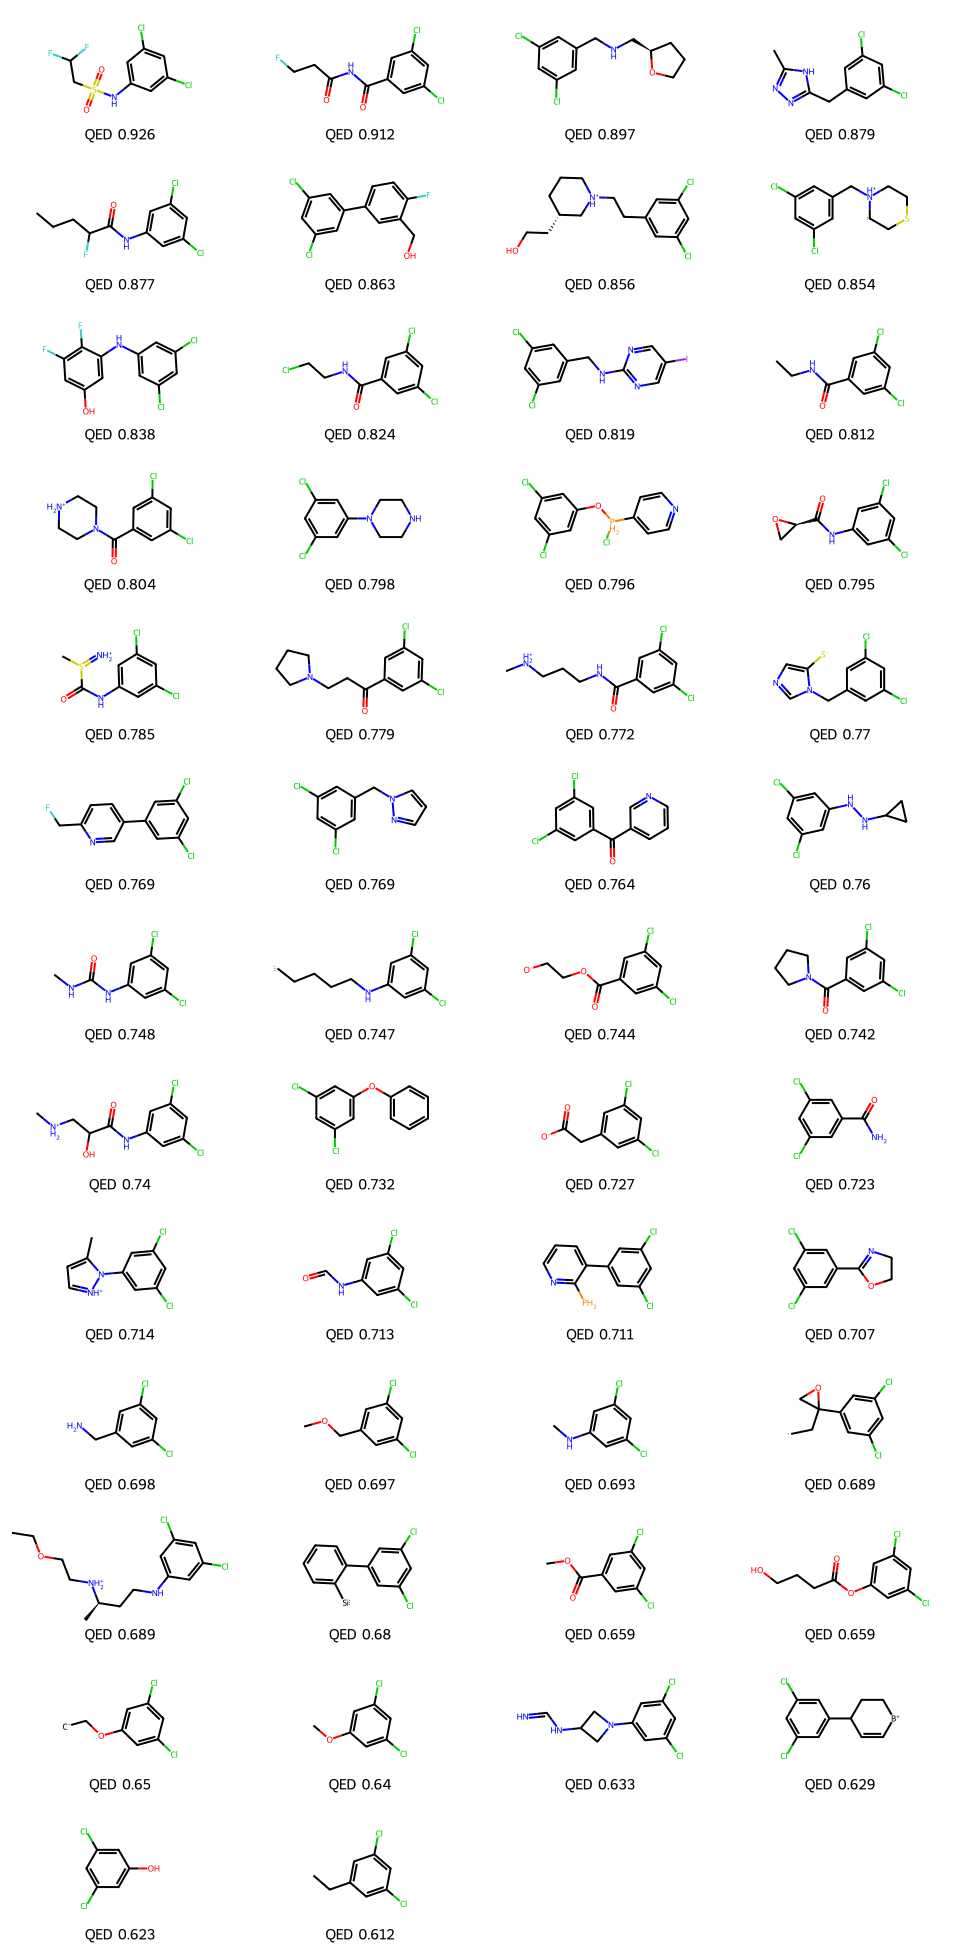

In [70]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules])

In [71]:
df_results = pd.concat(df_results, pd.DataFrame(molecules), ignore_index=True)

/tmp/ipykernel_31171/3426026396.py:1: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_results = df_results.append(pd.DataFrame(molecules), ignore_index=True)


In [73]:
len(df_results)

90

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

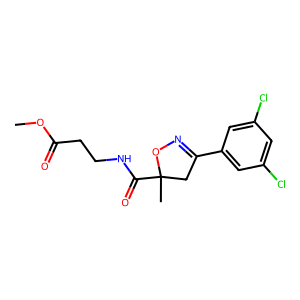

In [117]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

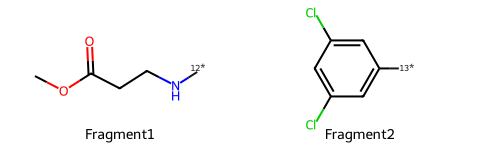

In [118]:
frag1, frag2 = 'COC(=O)CCN[12*]', '[13*](c2cc(Cl)cc(Cl)c2)' #'[11*]C1(CC#N)CN(S(=O)(=O)CC)C1', '[13*]c1ncnc2[nH]ccc12' #  'COC(=O)CCNC[11*]

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

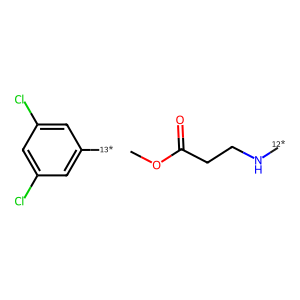

In [119]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [162]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-20}]'
input_text

'c14cc(Cl)cc(Cl)c1.C5(=O)CC6.CO5.N36.[*{5-20}]'

In [163]:
molecules = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules)

67

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


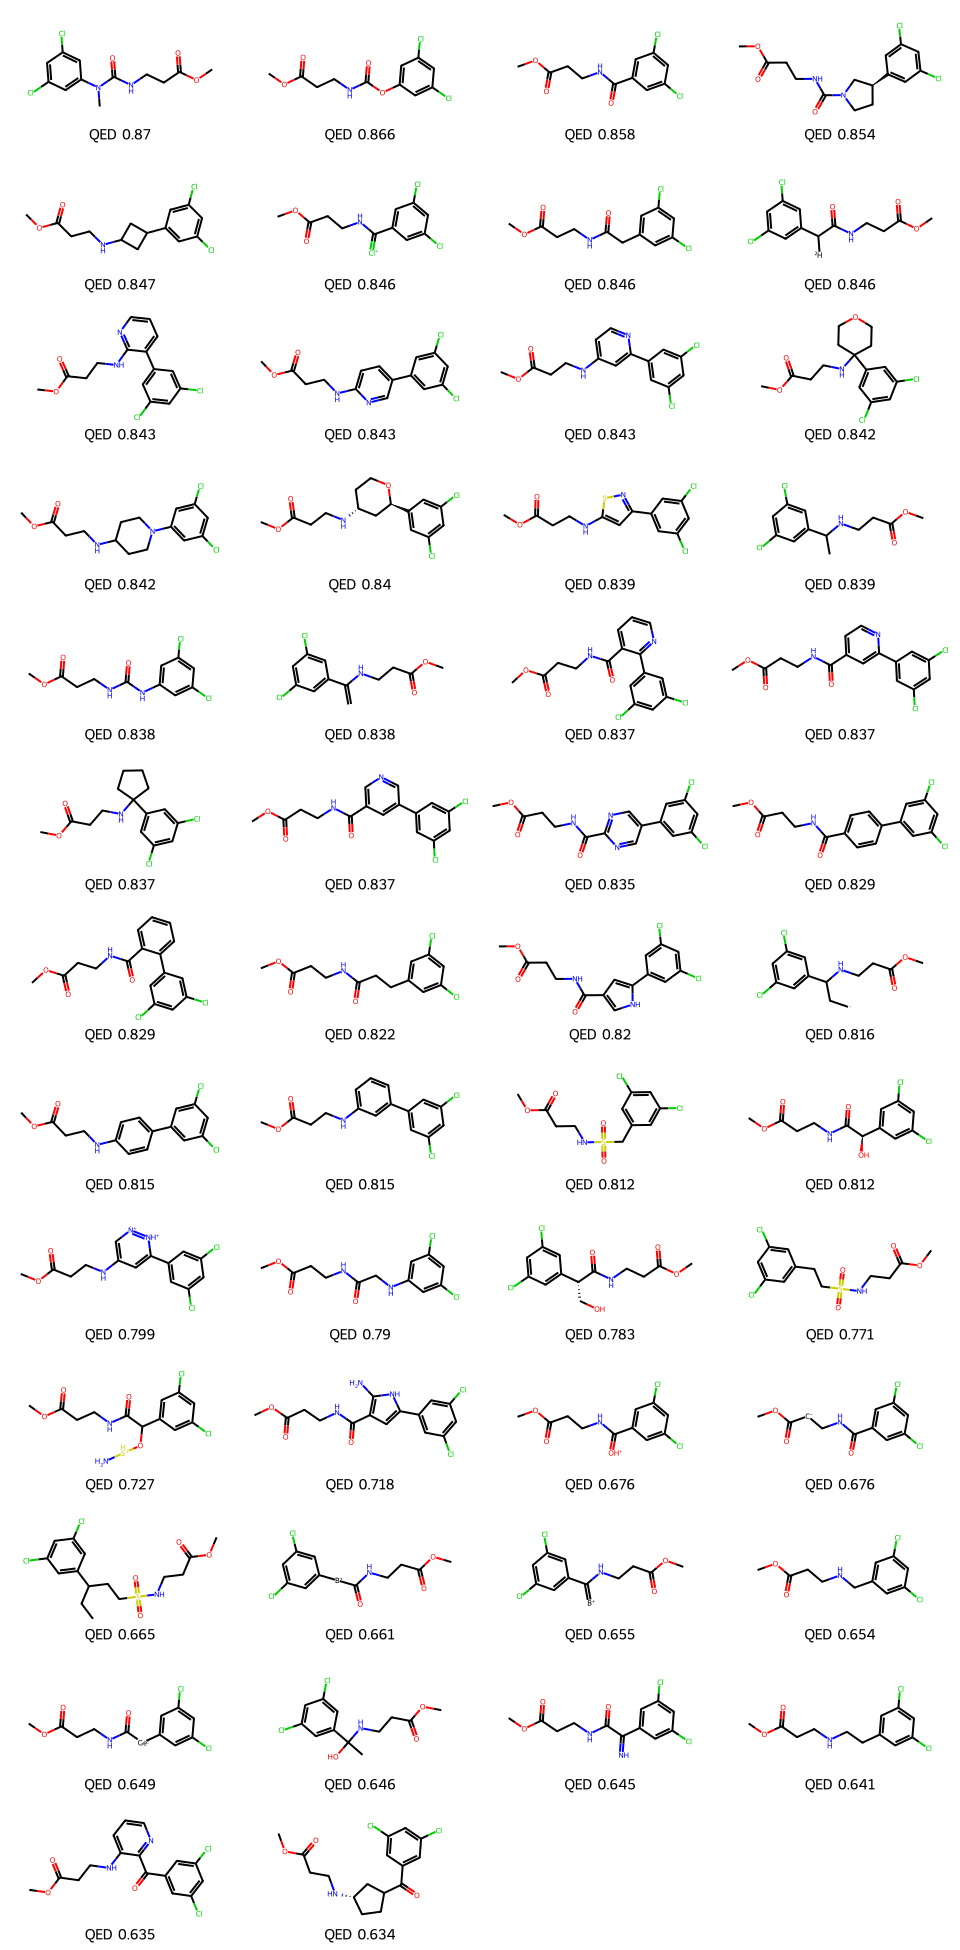

In [164]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules])

In [165]:
df_results.shape

(202, 2)

In [166]:
df_results = pd.concat([df_results, pd.DataFrame(molecules)], ignore_index=True)
print(len(df_results))
df_results.head()

269


,smiles,score
0,CCC1CCC1CC(=O)NCCC(=O)OC,0.699
1,COC(=O)CCNC(=O)COC(C)(C)C,0.680
2,COC(=O)CCNC(=O)C[Rg+],0.626
3,CCCC(=O)NCCC(=O)OC,0.615
4,CCC(=O)NCCC(=O)OC,0.591


## Mask in the center

COC(=O)CCN[12*].[13*](c2cc(Cl)cc(Cl)c2)


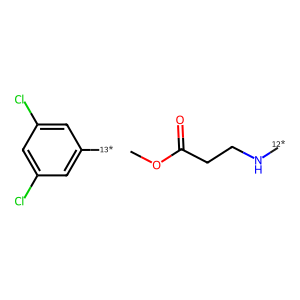

In [167]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [168]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['C2(=O)CC3', 'CO2', 'N13']

In [169]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['c13cc(Cl)cc(Cl)c1']

In [170]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['c14cc(Cl)cc(Cl)c1', 'C5(=O)CC6', 'CO5', 'N36']

In [171]:
input_text[1:]

['C5(=O)CC6', 'CO5', 'N36']

In [172]:
# select where to set mask
input_w_mask = '.'.join(input_text[1:]) + '.[*{5-18}].' + '.'.join(input_text[:1])
input_w_mask

'C5(=O)CC6.CO5.N36.[*{5-18}].c14cc(Cl)cc(Cl)c1'

In [173]:
molecules = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=100)
len(molecules)

68

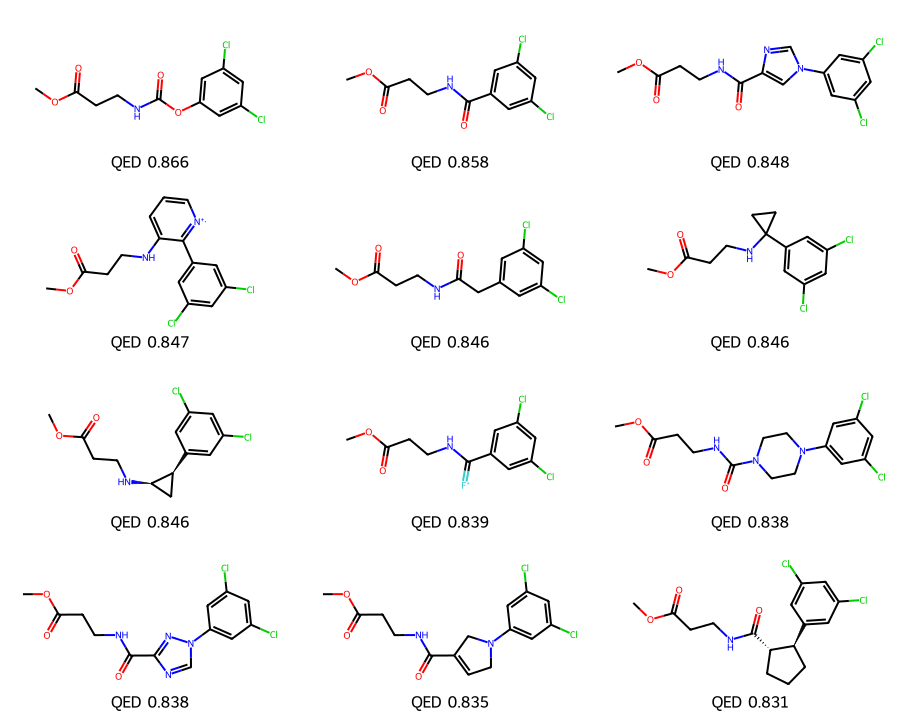

In [174]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules[:12]])

In [175]:
df_results = pd.concat([df_results, pd.DataFrame(molecules)], ignore_index=True)
print(len(df_results))
df_results.head()

337


,smiles,score
0,CCC1CCC1CC(=O)NCCC(=O)OC,0.699
1,COC(=O)CCNC(=O)COC(C)(C)C,0.680
2,COC(=O)CCNC(=O)C[Rg+],0.626
3,CCCC(=O)NCCC(=O)OC,0.615
4,CCC(=O)NCCC(=O)OC,0.591


In [176]:
#df_results.to_csv("../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv", index=False)

# Superstructure Generation

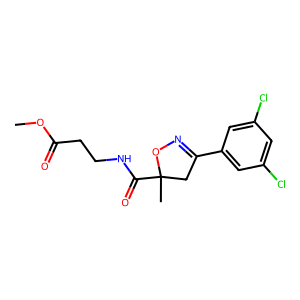

In [67]:
smiles = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles))

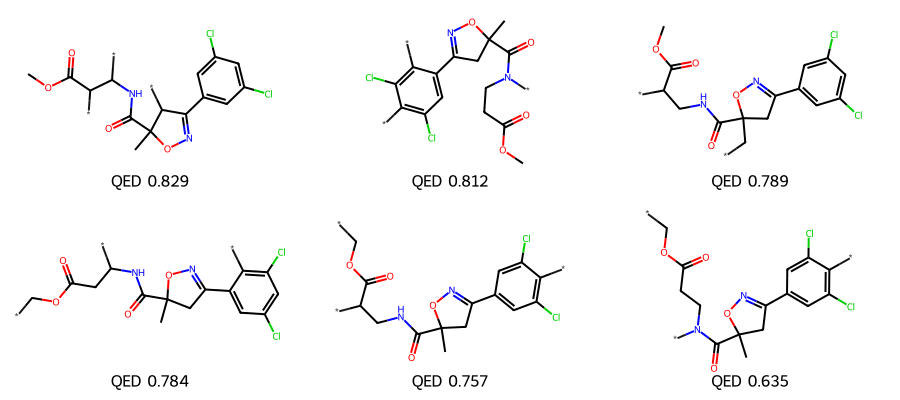

In [68]:
cores = Utils.attachable_points(smiles)[:6]
ms = [Chem.MolFromSmiles(_) for _ in cores]
Draw.MolsToGridImage(ms, molsPerRow=3, subImgSize=(300, 200), legends=['QED ' + str(_['score']) for _ in molecules])

In [69]:
safes = [Utils.smiles2safe(_) for _ in cores]
molecules = [gm.inference(smiles = _ + '.[*{15-15}]', num_molecules = 10, temperature = 1.5, noise = 1.0)[0] for _ in safes]

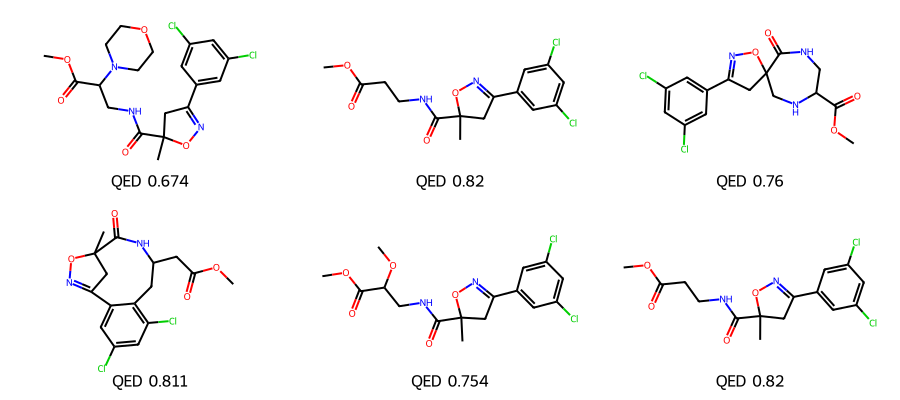

In [70]:
smiless = [_['smiles'] for _ in molecules]
ms = [Chem.MolFromSmiles(_) for _ in smiless]
Draw.MolsToGridImage(ms, molsPerRow=3, subImgSize=(300, 200), legends=['QED ' + str(_['score']) for _ in molecules])